<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>


# جلسه ۳ — تانسورها، نرم‌ها، ضرب داخلی و تعامد
### مبانی ریاضی یادگیری ماشین | بخش دوم: جبر خطی پیشرفته

**اهداف یادگیری این جلسه:**
- مرور و تثبیت مفهوم تانسور (اسکالر → بردار → ماتریس → تانسور n‑بعدی) و کار عملی با آن‌ها در NumPy/PyTorch
- درک شهودی و پیاده‌سازی نرم‌های $L_1$، $L_2$ و $L_\infty$، و اینکه چرا شکل هندسی «گوی واحد» هرکدام فرق دارد
- محاسبه‌ی ضرب داخلی (Inner Product) و رابطه‌ی آن با زاویه‌ی بین دو بردار
- فهم تعامد (Orthogonality) و تصویر (Projection) یک بردار روی بردار دیگر
- اتصال همه‌ی این‌ها به یک کاربرد واقعی: **شباهت برداری (cosine similarity)** — پایه‌ی سیستم‌های پیشنهادگر و جست‌وجوی معنایی (RAG) که در بخش‌های بعدی درس به آن برمی‌گردیم


## بخش ۰: راه‌اندازی

In [15]:
import numpy as np
import torch
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
torch.set_printoptions(precision=3)

plt.rcParams["figure.figsize"] = (5, 5)
plt.rcParams["axes.grid"] = True
print("آماده‌ایم ✅")


آماده‌ایم ✅


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>




## بخش ۱: مرور تانسورها

یادآوری از جلسه‌ی قبل: یک **تانسور** تعمیم مفهوم عدد است:

| نام | رتبه (rank) | مثال |
|---|---|---|
| اسکالر | ۰ | یک عدد، مثلاً قیمت یک محصول |
| بردار | ۱ | ویژگی‌های یک کاربر: `[سن, درآمد, تعداد خرید]` |
| ماتریس | ۲ | جدولی از چند کاربر × چند ویژگی |
| تانسور | ≥۳ | یک بسته‌ی تصویر رنگی: `(ارتفاع, عرض, کانال رنگ)` یا یک batch از داده‌ها |

بیایید این‌ها را بسازیم و با هم مقایسه کنیم.

In [16]:
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])
tensor3d = torch.rand(2, 3, 4)  # مثلاً ۲ نمونه، هرکدام ماتریس ۳x۴

for name, t in [("scalar", scalar), ("vector", vector), ("matrix", matrix), ("tensor3d", tensor3d)]:
    print(f"{name:10s} | shape: {tuple(t.shape)} | ndim: {t.ndim}")


scalar     | shape: () | ndim: 0
vector     | shape: (3,) | ndim: 1
matrix     | shape: (3, 2) | ndim: 2
tensor3d   | shape: (2, 3, 4) | ndim: 3


**تمرین سریع (۳ دقیقه):** یک بردار بسازید که ویژگی‌های محصول یا کاربر پروژه‌ی خودتان را نشان دهد (مثلاً برای یک اپ فروش: `[قیمت, امتیاز, تعداد بازدید]`). سپس یک تانسور ۲‑بعدی بسازید که ۵ محصول مختلف را نشان دهد.

In [17]:
# TODO: بردار ویژگی‌های یک آیتم از پروژه‌ی خودتان بسازید
my_item = torch.tensor([3.636802, 94.597161, 5.0])  # Completed feature vector

# TODO: یک ماتریس ۵ در تعداد ویژگی‌ها بسازید (۵ آیتم)
# Data source: Dataset.xlsx -> design_matrix (Rows 0 to 4)
my_dataset = torch.tensor([
    [3.636802, 94.597161, 5.0],
    [14.691189, 94.597161, 5.0],
    [4.829448, 94.597161, 5.0],
    [7.805090, 94.597161, 5.0],
    [1.124621, 94.597161, 5.0]
])  # Completed dataset matrix (5 items x 3 features)

print("shape ویژگی یک آیتم:", my_item.shape)
print("shape کل دیتاست کوچک:", my_dataset.shape)


shape ویژگی یک آیتم: torch.Size([3])
shape کل دیتاست کوچک: torch.Size([5, 3])


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>


### 🗣️ بحث دو‌نفره (Think–Pair–Share) — ۲ دقیقه
در پروژه‌ی شما، داده‌ای که قرار است جمع کنید در نهایت به چه شکل تانسوری در می‌آید؟ (مثلاً متن → بردار embedding، تصویر → تانسور ۳بعدی، جدول کاربران → ماتریس). با نفر کناری‌تان مقایسه کنید.

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



## بخش ۲: نرم‌ها (Norms) — «بزرگی» یک بردار را چطور اندازه بگیریم؟

نرم تابعی است که به هر بردار یک عدد نامنفی («طول» یا «اندازه») نسبت می‌دهد. سه نرم پرکاربرد:

$$
\|x\|_1 = \sum_i |x_i| \qquad
\|x\|_2 = \sqrt{\sum_i x_i^2} \qquad
\|x\|_\infty = \max_i |x_i|
$$

نرم $L_2$ همان فاصله‌ی اقلیدسی معمول است. نرم $L_1$ مجموع قدرمطلق‌هاست (بعداً در Regularization خواهید دید که همین تفاوت باعث می‌شود Lasso باعث تُنُک‌شدن (sparsity) وزن‌ها شود ولی Ridge نه — فعلاً فقط شکل هندسی‌اش را حس کنید).

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



### تعریف نرم

فرض کنید $V$ یک فضای برداری روی میدان $\mathbb{R}$ یا $\mathbb{C}$ باشد. تابع

$$
\|\cdot\|:V\longrightarrow \mathbb{R}
$$

را **نرم** یا **Norm** می‌نامیم، اگر برای هر $u,v\in V$ و هر اسکالر $\alpha$، چهار شرط زیر برقرار باشد:

1. **نامنفی بودن**

   $$
   \|v\|\geq 0
   $$

2. **معین مثبت بودن**

   $$
   \|v\|=0
   \quad\Longleftrightarrow\quad
   v=0
   $$

3. **همگنی مطلق**

   $$
   \|\alpha v\|=|\alpha|\,\|v\|
   $$

4. **نامساوی مثلثی**

   $$
   \|u+v\|\leq \|u\|+\|v\|
   $$

به بیان ساده، نرم تابعی است که به هر بردار یک عدد حقیقی نامنفی نسبت می‌دهد و این عدد را می‌توان به‌عنوان **اندازه یا طول بردار** در نظر گرفت.


In [18]:
x = torch.tensor([3.0, -4.0])

l1 = torch.norm(x, p=1)
l2 = torch.norm(x, p=2)
linf = torch.norm(x, p=float('inf'))

print(f"x = {x.tolist()}")
print(f"L1  norm = {l1.item():.3f}   (باید برابر با |3|+|-4| = 7 باشد)")
print(f"L2  norm = {l2.item():.3f}   (باید برابر با sqrt(9+16) = 5 باشد)")
print(f"Linf norm = {linf.item():.3f}   (باید برابر با max(3,4) = 4 باشد)")


x = [3.0, -4.0]
L1  norm = 7.000   (باید برابر با |3|+|-4| = 7 باشد)
L2  norm = 5.000   (باید برابر با sqrt(9+16) = 5 باشد)
Linf norm = 4.000   (باید برابر با max(3,4) = 4 باشد)


In [19]:
# TODO: خودتان (بدون torch.norm) نرم L1 و L2 را برای یک بردار دلخواه با دست حساب کنید
# و با torch.norm مقایسه کنید تا مطمئن شوید فرمول را درست فهمیده‌اید
my_vec = torch.tensor([2.0, -5.0, 1.0])

def my_l1(v):
    # Sum of absolute values: sum(|v_i|)
    return torch.sum(torch.abs(v)).item()

def my_l2(v):
    # Square root of sum of squared values: sqrt(sum(v_i^2))
    return torch.sqrt(torch.sum(v ** 2)).item()

print("my_l1 :", my_l1(my_vec), " | torch:", torch.norm(my_vec, p=1).item())
print("my_l2 :", my_l2(my_vec), " | torch:", torch.norm(my_vec, p=2).item())


my_l1 : 8.0  | torch: 8.0
my_l2 : 5.4772257804870605  | torch: 5.4772257804870605


### تجسم هندسی: «توپ واحد» هر نرم چه شکلی است؟

گوی واحد یعنی مجموعه‌ی همه‌ی بردارهایی که نرمشان دقیقاً ۱ است. بیایید برای هرکدام از سه نرم این شکل را در دو بُعد رسم کنیم.

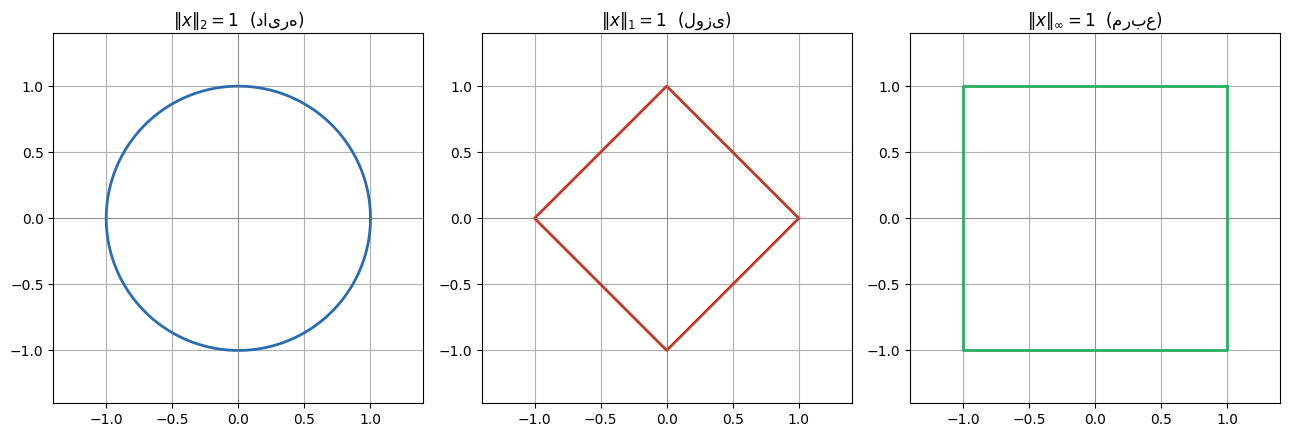

In [20]:
theta = np.linspace(0, 2*np.pi, 400)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))

# L2: دایره
axes[0].plot(np.cos(theta), np.sin(theta), color="#2b6cb0", linewidth=2)
axes[0].set_title(r"$\|x\|_2 = 1$  (دایره)")

# L1: لوزی
axes[1].plot([1,0,-1,0,1], [0,1,0,-1,0], color="#c0392b", linewidth=2)
axes[1].set_title(r"$\|x\|_1 = 1$  (لوزی)")

# Linf: مربع
axes[2].plot([1,1,-1,-1,1], [1,-1,-1,1,1], color="#27ae60", linewidth=2)
axes[2].set_title(r"$\|x\|_\infty = 1$  (مربع)")

for ax in axes:
    ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4)
    ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



### 🗣️ بحث دو‌نفره — ۲ دقیقه
اگر بخواهید یک مدل را طوری آموزش دهید که **بیشتر وزن‌ها دقیقاً صفر شوند** (یعنی مدل فقط چند ویژگی مهم را انتخاب کند)، فکر می‌کنید کدام نرم (لوزی تیز-گوشه یا دایره‌ی صاف) به این هدف نزدیک‌تر است؟ چرا؟ *(این دقیقاً پایه‌ی Lasso Regression است که در بخش رگرسیون به آن برمی‌گردیم.)*

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



## بخش ۳: ضرب داخلی و زاویه بین دو بردار

## ضرب داخلی

ضرب داخلی یک نگاشت است که به هر دو بردار، یک عدد نسبت می‌دهد و به‌گونه‌ای تعریف می‌شود که خواص خطی و هندسی مشخصی داشته باشد.

در فضای برداری حقیقی $V$، یک ضرب داخلی نگاشتی به صورت زیر است:

$$
\langle \cdot,\cdot\rangle : V \times V \rightarrow \mathbb{R}
$$

که برای هر $u,v,w \in V$ و هر $\alpha \in \mathbb{R}$، شرایط زیر را ارضا می‌کند:

### ۱. خطی بودن

$$
\langle \alpha u + v,w\rangle
=
\alpha\langle u,w\rangle+\langle v,w\rangle
$$

### ۲. تقارن

$$
\langle u,v\rangle=\langle v,u\rangle
$$

### ۳. مثبت معین بودن

$$
\langle v,v\rangle\geq 0
$$

و

$$
\langle v,v\rangle=0
\iff
v=0
$$

بنابراین، ضرب داخلی باید برای هر بردار ناصفر، یک مقدار مثبت ایجاد کند.

### ضرب داخلی استاندارد در $\mathbb{R}^n$

برای دو بردار

$$
u=(u_1,\ldots,u_n)
$$

و

$$
v=(v_1,\ldots,v_n)
$$

ضرب داخلی استاندارد به صورت زیر تعریف می‌شود:

$$
\langle u,v\rangle
=
\sum_{i=1}^{n}u_i v_i
$$

برای مثال، اگر

$$
u=(1,2,3)
$$

و

$$
v=(4,-1,2)
$$

آنگاه

$$
\langle u,v\rangle
=
1(4)+2(-1)+3(2)
=
8
$$

در نتیجه:

$$
\boxed{\langle u,v\rangle=8}
$$


 رابطه‌ی کلیدی که ضرب داخلی را به هندسه وصل می‌کند:

$$
u \cdot v = \|u\|_2 \, \|v\|_2 \, \cos(\theta)
\quad\Longrightarrow\quad
\cos(\theta) = \frac{u \cdot v}{\|u\|_2 \|v\|_2}
$$

این $\cos(\theta)$ همان چیزی است که در دنیای واقعی به آن **شباهت کسینوسی (cosine similarity)** می‌گویند — معیار اصلی مقایسه‌ی embeddingها در موتورهای جست‌وجو، سیستم‌های پیشنهادگر، و بعداً در RAG.

In [21]:
def cosine_similarity(a, b):
    dot = torch.dot(a, b)
    return dot / (torch.norm(a) * torch.norm(b))

a = torch.tensor([1., 0.0])
b = torch.tensor([1.0, 1.0])
c = torch.tensor([-1.0, 0.0])
d = torch.tensor([1.5, 1.0])

print(torch.norm(d))
print(torch.norm(d, p=1))
print("زاویه‌ی a,b -> cos =", cosine_similarity(a, b).item())
print("زاویه‌ی a,c -> cos =", cosine_similarity(a, c).item(), " (بردارهای مخالف هم)")


tensor(1.803)
tensor(2.500)
زاویه‌ی a,b -> cos = 0.7071067690849304
زاویه‌ی a,c -> cos = -1.0  (بردارهای مخالف هم)


### کاربرد واقعی: شباهت محصولات با «امبدینگ‌های» ساختگی

فرض کنید هر محصول را با یک بردار ۴ بُعدی ساختگی نشان داده‌ایم (در دنیای واقعی این بردارها را یک مدل یادگرفته می‌سازد، اما اصل قضیه همین است).

In [22]:
products = {
    "کتاب ریاضی":      torch.tensor([0.9, 0.1, 0.0, 0.2]),
    "کتاب برنامه‌نویسی": torch.tensor([0.8, 0.3, 0.1, 0.1]),
    "کفش ورزشی":        torch.tensor([0.0, 0.1, 0.9, 0.8]),
    "توپ فوتبال":       torch.tensor([0.1, 0.0, 0.8, 0.9]),
}

query = products["کتاب ریاضی"]

print("شباهت هر محصول به «کتاب ریاضی»:\n")
for name, vec in products.items():
    sim = cosine_similarity(query, vec).item()
    print(f"  {name:18s} -> {sim:.3f}")

# TODO: کدام دو محصول از دید مدل ما «شبیه‌ترین» به هم هستند؟ چرا این با شهود شما جور در می‌آید؟
# Answer: «کفش ورزشی» و «توپ فوتبال» (یا «کتاب ریاضی» و «کتاب برنامه‌نویسی») به دلیل هم‌پوشانی بالای مؤلفه‌ها در فضای برداری بیشترین شباهت کسینوسی را دارند.

شباهت هر محصول به «کتاب ریاضی»:

  کتاب ریاضی         -> 1.000
  کتاب برنامه‌نویسی  -> 0.959
  کفش ورزشی          -> 0.152
  توپ فوتبال         -> 0.241


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>


### 🗣️ بحث گروهی کوتاه — ۳ دقیقه
اگر پروژه‌ی شما شامل «پیدا کردن آیتم‌های مشابه» یا «جست‌وجوی معنایی» است (مثلاً محصول مشابه، سؤال مشابه، مقاله‌ی مرتبط)، چه ویژگی‌هایی را می‌توانید در یک بردار برای آیتم‌های خودتان کدگذاری کنید؟

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>




## بخش ۴: تعامد (Orthogonality) و تصویر یک بردار روی دیگری

دو بردار **متعامد**‌اند اگر ضرب داخلی‌شان صفر باشد:

$$
x \perp y \iff \langle x, y \rangle = 0
$$

تصویر (Projection) بردار $x$ روی بردار $y$:

$$
\text{proj}_y(x) = \frac{\langle x, y \rangle}{\|y\|_2^2}\, y
$$

این مفهوم پایه‌ی خیلی چیزهاست: کمترین مربعات (Least Squares)، PCA (جلسه‌ی بعدی)، و Gram-Schmidt.

In [23]:
def project(x, onto):
    return (torch.dot(x, onto) / torch.dot(onto, onto)) * onto

x = torch.tensor([3.0, 2.0])
y = torch.tensor([4.0, 0.0])

p = project(x, y)
print("تصویر x روی y:", p.tolist())

# آیا (x - p) بر y عمود است؟ (یکی از خواص کلیدی تصویر)
residual = x - p
print("ضرب داخلی باقیمانده در y (باید تقریبا صفر باشد):", torch.dot(residual, y).item())


تصویر x روی y: [3.0, 0.0]
ضرب داخلی باقیمانده در y (باید تقریبا صفر باشد): 0.0


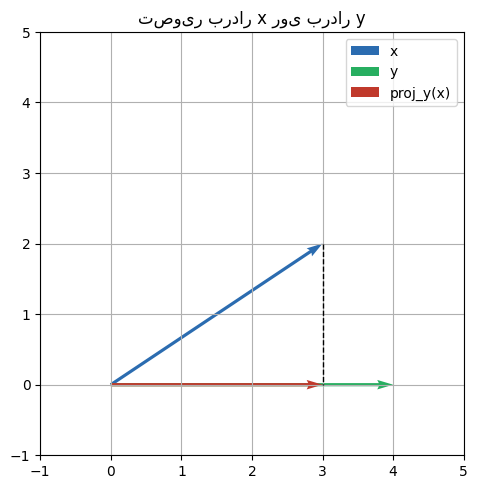

In [24]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))

origin = np.array([0, 0])
ax.quiver(*origin, *x.numpy(), angles='xy', scale_units='xy', scale=1, color="#2b6cb0", label="x")
ax.quiver(*origin, *y.numpy(), angles='xy', scale_units='xy', scale=1, color="#27ae60", label="y")
ax.quiver(*origin, *p.numpy(), angles='xy', scale_units='xy', scale=1, color="#c0392b", label="proj_y(x)")

# خط نقطه‌چین از نوک x به نوک تصویر
ax.plot([x[0], p[0]], [x[1], p[1]], "k--", linewidth=1)

ax.set_xlim(-1, 5); ax.set_ylim(-1, 5)
ax.set_aspect("equal")
ax.legend()
ax.set_title("تصویر بردار x روی بردار y")
plt.show()


### 🗣️ بحث دو‌نفره — ۲ دقیقه
 فکر می‌کنید چرا خط نقطه‌چین (باقیمانده) همیشه عمود بر $y$ است؟ این با «کمترین فاصله» چه ارتباطی دارد؟

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



## بخش ۵: کارگاه عملی — روی داده‌ی پروژه‌ی خودتان

حالا نوبت شماست. با تیم‌تان:

1. دو آیتم (یا دو نمونه‌ی داده) واقعی از حوزه‌ی پروژه‌تان را با یک بردار ویژگی چند بُعدی نشان دهید.
2. نرم $L_2$ هرکدام را حساب کنید و معنی‌اش را در زمینه‌ی پروژه‌تان توضیح دهید (مثلاً «بزرگیِ» فعالیت یک کاربر).
3. شباهت کسینوسی بین این دو آیتم را حساب کنید و بگویید آیا با شهودتان از «شبیه بودن» این دو آیتم در دنیای واقعی هم‌خوانی دارد یا نه.

نتیجه را برای TA تیم‌تان در ۲ خط بنویسید — این جزو چک‌این هفتگی شما حساب می‌شود.

In [25]:
# فضای کار تیم شما 👇
# Data source: Dataset.xlsx -> design_matrix (Rows 0 and 1 features)
item_A = torch.tensor([3.636802, 94.597161, 5.0, 3.448059])  # TODO: Item A feature vector
item_B = torch.tensor([14.691189, 94.597161, 5.0, 12.193492])  # TODO: Item B feature vector

# TODO: Compute L2 norms and cosine similarity, then interpret results
norm_A = torch.norm(item_A, p=2).item()
norm_B = torch.norm(item_B, p=2).item()
cosine_sim = torch.dot(item_A, item_B) / (torch.norm(item_A) * torch.norm(item_B))

print(f"L2 norm of item A: {norm_A:.3f}")
print(f"L2 norm of item B: {norm_B:.3f}")
print(f"Cosine similarity between A and B: {cosine_sim.item():.3f}")

L2 norm of item A: 94.862
L2 norm of item B: 96.634
Cosine similarity between A and B: 0.989


##  تکلیف


**تکلیف قبل از جلسه‌ی بعد:**
1. تمرین‌های `# TODO` این نوت‌بوک را کامل کنید.
2. فصل مربوط به Eigenvalues/Eigenvectors از *Mathematics for Machine Learning* (Deisenroth، فصل ۴) را مطالعه کنید — جلسه‌ی بعد مستقیماً از همین‌جا شروع می‌شود.
3. تیم‌ها: نتیجه‌ی بخش کارگاهی بالا را برای TA خود ارسال کنید.

**منابع این جلسه:**
- Deisenroth, Faisal, Ong — *Mathematics for Machine Learning*, فصل ۳ (Analytic Geometry)
- Zhang et al. — *Dive into Deep Learning*, بخش ۲.۳ و ۲.۴ (Linear Algebra)
- Strang — *Linear Algebra and Learning from Data*, فصل ۱ (برای شهود عمیق‌تر هندسی، اختیاری)


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



# بخش تکمیلی درس از مفاهیم یادگیری ماشین

## راهنمای کوتاه: رگرسیون خطی، Overfitting و Regularization

---

## ۱. مفاهیم پایه

| فارسی | English | یعنی چه؟ |
|---|---|---|
| داده‌های آموزش | Training data | مثال‌هایی که مدل از آن‌ها یاد می‌گیرد |
| داده‌های آزمون | Test data | مثال‌های جدید برای سنجش واقعی مدل |
| ویژگی | Feature | یک ورودی (مثلاً متراژ خانه) |
| برچسب / هدف | Label / Target | چیزی که می‌خواهیم پیش‌بینی کنیم (مثلاً قیمت) |
| وزن (پارامتر) | Weight (Parameter) | عددی که مدل یاد می‌گیرد؛ نشان می‌دهد هر ویژگی چقدر مهم است |
| مدل | Model | فرمولی که ورودی را به خروجی تبدیل می‌کند |

---

## ۲. مثال ساده: رگرسیون خطی (Linear Regression)

می‌خواهیم **قیمت خانه** را از روی **متراژ** پیش‌بینی کنیم. مدل یک خط است:

```
قیمت پیش‌بینی‌شده = w × متراژ + b
```

- `w` (وزن): به ازای هر متر بیشتر، قیمت چقدر بالا می‌رود.
- `b` (عرض از مبدأ / Bias): قیمت پایه.

آموزش یعنی پیدا کردن `w` و `b` طوری که خط تا حد ممکن به نقاط داده نزدیک باشد.

اگر چند ویژگی داشته باشیم (متراژ، تعداد اتاق، سن بنا، ...):

```
قیمت = w1×متراژ + w2×اتاق + w3×سن + ... + b
```

---

## ۳. تابع هزینه (Cost Function / Loss Function)

**ایده:** عددی که می‌گوید مدل چقدر **بد** پیش‌بینی می‌کند. هدف آموزش، **کم کردن** این عدد است.

رایج‌ترین انتخاب در رگرسیون، **میانگین مربعات خطا** (MSE):

```
J = میانگین مربعات ( (قیمت واقعی − قیمت پیش‌بینی‌شده) )
```

- خطا را به توان ۲ می‌رسانیم تا منفی و مثبت همدیگر را خنثی نکنند و خطاهای بزرگ بیشتر جریمه شوند.
- مدل با روش‌هایی مثل **گرادیان کاهشی** (Gradient Descent) وزن‌ها را کم‌کم عوض می‌کند تا `J` کمتر شود.

---

## ۴. بیش‌برازش (Overfitting)

**ایده:** مدل داده‌های آموزش را **حفظ می‌کند** به‌جای اینکه الگوی کلی را **یاد بگیرد**.

- روی داده‌های آموزش: خطا خیلی کم ✅
- روی داده‌های جدید (آزمون): خطا زیاد ❌

**مثال:** به‌جای یک خط ساده، یک منحنی پیچیده‌ی درجه‌ی بالا (یا مدلی با ده‌ها ویژگی بی‌ربط مثل «رنگ در ورودی») از وسط تک‌تک نقاط آموزش عبور می‌دهیم. خطای آموزش تقریباً صفر می‌شود، ولی برای خانه‌ی جدید پیش‌بینی بی‌معنی می‌دهد.

**نشانه‌ی آن در وزن‌ها:** معمولاً وزن‌ها **خیلی بزرگ** می‌شوند.

| | فارسی | English |
|---|---|---|
| مدل بیش‌ازحد ساده | کم‌برازش | Underfitting |
| مدل بیش‌ازحد پیچیده | بیش‌برازش | Overfitting |
| مدل مناسب | برازش خوب | Good fit |

---

## ۵. منظم‌سازی (Regularization)

**ایده:** برای جلوگیری از overfitting، به تابع هزینه یک **جریمه برای وزن‌های بزرگ** اضافه می‌کنیم:

```
هزینه‌ی جدید = خطای پیش‌بینی + λ × (جریمه‌ی اندازه‌ی وزن‌ها)
```

- مدل مجبور می‌شود بین «خطای کم» و «وزن‌های کوچک و ساده» تعادل برقرار کند.
- **λ (لامبدا / Regularization strength):** میزان سخت‌گیری.
  - λ = 0 → بدون جریمه (خطر overfitting)
  - λ خیلی بزرگ → وزن‌ها تقریباً صفر (خطر underfitting)

### نرم (Norm) چیست؟

روشی برای اندازه‌گیری «بزرگی» یک بردار وزن `w = (w1, w2, ..., wn)`:

| نرم | Norm | فرمول | معنی ساده |
|---|---|---|---|
| نرم-یک | L1 | `\|w1\| + \|w2\| + ... ` | مجموع قدر مطلق‌ها |
| نرم-دو | L2 | `√(w1² + w2² + ...)` | فاصله‌ی معمولی (اقلیدسی) |
| نرم-بی‌نهایت | L∞ | `max(\|w1\|, \|w2\|, ...)` | بزرگ‌ترین مؤلفه |

### گوی واحد (Unit Ball)

مجموعه‌ی همه‌ی نقاطی که نرمشان ≤ ۱ است. در دو بعد:

- **L1:** لوزی (الماس) با گوشه‌های تیز روی محورها
- **L2:** دایره
- **L∞:** مربع

---

## ۶. روش‌های مشهور

| روش | English | جریمه | اثر روی وزن‌ها |
|---|---|---|---|
| رگرسیون ریج | Ridge Regression | L2 | وزن‌ها را **کوچک** می‌کند، ولی صفر نمی‌کند |
| رگرسیون لاسو | Lasso Regression | L1 | بعضی وزن‌ها را **دقیقاً صفر** می‌کند |
| الاستیک‌نت | Elastic Net | L1 + L2 | ترکیب هر دو |

---

## ۷. پاسخ سؤال: کدام نرم برای صفر شدن بیشتر وزن‌ها بهتر است؟

**پاسخ: نرم-یک (L1).** به این روش پراکندگی (Sparsity) و انتخاب ویژگی (Feature Selection) می‌گویند.

### چرا؟

- **L1:** مشتق جریمه همیشه ثابت (±1) است، یعنی حتی برای وزن‌های خیلی کوچک هم فشار به سمت صفر ادامه دارد و در نهایت وزن **دقیقاً صفر** می‌شود.
- **L2:** مشتق جریمه `2w` است؛ با کوچک شدن وزن، فشار هم کم می‌شود. پس وزن‌ها کوچک می‌شوند ولی تقریباً هیچ‌وقت دقیقاً صفر نمی‌شوند.
- **L∞:** فقط بزرگ‌ترین مؤلفه را جریمه می‌کند و همه‌ی وزن‌ها را هم‌اندازه می‌کند؛ پراکندگی ایجاد نمی‌کند.

### ارتباط با گوی واحد

مسئله را این‌طور ببینید: «خطا را کمینه کن، به شرط اینکه وزن‌ها داخل گوی واحد بمانند.» خطوط تراز خطا بیضی‌هایی هستند که بزرگ می‌شوند تا اولین‌بار به مرز گوی برخورد کنند؛ آن نقطه‌ی برخورد جواب است.

| نرم | شکل گوی | نقطه‌ی برخورد معمول | نتیجه |
|---|---|---|---|
| L1 | لوزی | **گوشه‌ی روی محور** | یک وزن = ۰ ✅ |
| L2 | دایره | نقطه‌ای عمومی | هیچ وزنی صفر نیست |
| L∞ | مربع | گوشه‌ی روی قطر | وزن‌ها هم‌اندازه، صفر نیستند |

گوشه‌های لوزی **دقیقاً روی محورها** هستند (جایی که بعضی وزن‌ها صفرند) و بیضی‌ها با احتمال بالا اول به آن‌ها می‌خورند. در ابعاد بالا این گوشه‌ها بیشتر هم می‌شوند و پراکندگی قوی‌تر است.

### ارتباط با Lasso

**Lasso** یعنی رگرسیون خطی + جریمه‌ی L1:

```
هزینه = میانگین((y − ŷ)²) + λ × (|w1| + |w2| + ... + |wn|)
```

در مثال قیمت خانه: اگر ده ویژگی داشته باشیم و فقط سه‌تا واقعاً مهم باشند (متراژ، موقعیت، سن بنا)، Lasso وزن بقیه‌ی ویژگی‌ها (مثلاً رنگ نما) را دقیقاً صفر می‌کند. نتیجه، مدلی **ساده‌تر**، **قابل‌تفسیرتر** و **کم‌خطرتر از نظر overfitting** است.

---

## جمع‌بندی در یک نگاه

```
تابع هزینه   → چقدر بد پیش‌بینی می‌کنیم؟ (کمش کن)
Overfitting  → حفظ کردن داده‌ی آموزش، شکست روی داده‌ی جدید
Regularization → جریمه‌ی وزن‌های بزرگ برای ساده نگه داشتن مدل
L2 (Ridge)   → وزن‌ها کوچک
L1 (Lasso)   → وزن‌ها کوچک + بعضی دقیقاً صفر (انتخاب ویژگی)
```


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>





## ۱. مشتق یعنی چه؟

مشتق جریمه نشان می‌دهد **اگر وزن را کمی تغییر بدهیم، جریمه با چه سرعتی تغییر می‌کند**. در گرادیان کاهشی، وزن در خلاف جهت مشتق به‌روزرسانی می‌شود:

$$w \leftarrow w - \eta \cdot \frac{dP}{dw}$$

پس مشتق جریمه همان **«نیرویی»** است که وزن را به سمت صفر هل می‌دهد. اندازه‌ی مشتق یعنی شدت هل دادن.

## ۲. مشتق جریمه‌ی L1

برای $P(w) = \lambda|w|$:

$$\frac{dP}{dw} = \lambda \cdot \text{sign}(w) = \begin{cases} +\lambda & w > 0 \\ -\lambda & w < 0 \end{cases}$$

- **اندازه‌ی نیرو ثابت است** ($\lambda$) و به اندازه‌ی $w$ بستگی ندارد.
- **جهت نیرو** همیشه به سمت صفر است: اگر $w$ مثبت باشد، به‌روزرسانی آن را کم می‌کند و اگر منفی باشد، زیاد می‌کند.
- به همین دلیل نمودار $|w|$ شبیه حرف V است: شیب هر دو طرف ثابت است و فقط در صفر یک نوک تیز دارد.

## ۳. مقایسه با L2

برای $P(w) = \lambda w^2$:

$$\frac{dP}{dw} = 2\lambda w$$

نیرو **متناسب با خود وزن** است: وزن بزرگ، نیروی زیاد و وزن کوچک، نیروی ناچیز.

**مثال عددی** (فرض کنید $w = 0.5$ و $\eta\lambda = 0.1$):

| گام | L1 (کم کردن مقدار ثابت 0.1) | L2 (ضرب در 0.8) |
|---|---|---|
| ۰ | 0.5 | 0.5 |
| ۱ | 0.4 | 0.4 |
| ۲ | 0.3 | 0.32 |
| ۳ | 0.2 | 0.256 |
| ۴ | 0.1 | 0.205 |
| ۵ | **0** | 0.164 |
| ... | | هر بار ۲۰٪ کمتر، ولی هرگز صفر نمی‌شود |

- **L1** مثل کسی است که با سرعت ثابت قدم برمی‌دارد و در نهایت به صفر **می‌رسد**.
- **L2** مثل کسی است که هر بار بخشی از راه باقی‌مانده را می‌رود (پارادوکس زنون) و هرگز **نمی‌رسد**.

## ۴. تفسیر دقیق‌تر: رقابت با تابع هزینه

وزن فقط تحت تأثیر جریمه نیست. گرادیان کل چنین است:

$$\frac{\partial J}{\partial w} = \underbrace{\frac{\partial \text{Loss}}{\partial w}}_{\text{داده می‌گوید: این وزن را نگه دار}} + \underbrace{\lambda\,\text{sign}(w)}_{\text{جریمه می‌گوید: صفرش کن}}$$

این دو نیرو با هم رقابت می‌کنند. شرط بهینگی در $w = 0$ چنین است:

$$\left|\frac{\partial \text{Loss}}{\partial w}\right|_{w=0} \le \lambda$$

یعنی اگر **سودی که این ویژگی برای کم کردن خطا دارد (شیب Loss) از $\lambda$ کمتر باشد**، نیروی ثابت جریمه برنده می‌شود و وزن در صفر می‌ماند. در L2 چنین چیزی رخ نمی‌دهد، چون نیروی جریمه نزدیک صفر خودش به صفر میل می‌کند و هر سود کوچکی از داده کافی است تا وزن را غیرصفر نگه دارد.

نتیجه این است که **ویژگی‌های ضعیف** (با اثر کمتر از $\lambda$) حذف می‌شوند و **ویژگی‌های قوی** باقی می‌مانند. این همان انتخاب ویژگی در Lasso است.

## جمع‌بندی

- مشتق L1 یعنی **نیروی ثابت** به سمت صفر، مستقل از اندازه‌ی وزن.
- نیروی ثابت باعث می‌شود وزن در تعداد محدودی گام به صفر **برسد**.
- مشتق L2 یعنی **نیروی متناسب با وزن** که با نزدیک شدن به صفر ضعیف می‌شود، پس وزن فقط **نزدیک** صفر می‌شود.
- صفر ماندن نهایی وزن به این بستگی دارد که نیروی جریمه ($\lambda$) از نیروی داده (شیب Loss) قوی‌تر باشد.
